In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
df=pd.read_csv('penguins_size.csv')

In [3]:
df.shape

(344, 7)

In [4]:
df.isnull().sum()

,0
species,0
island,0
culmen_length_mm,2
culmen_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,10


In [5]:
df.head(3)

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE


In [9]:
df=df.dropna()
df.shape

(334, 7)

In [11]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['sex']=le.fit_transform(df['sex'])
df['island']=le.fit_transform(df['island'])
df['species']=le.fit_transform(df['species'])

/tmp/ipykernel_519/1764208789.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sex']=le.fit_transform(df['sex'])
/tmp/ipykernel_519/1764208789.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['island']=le.fit_transform(df['island'])
/tmp/ipykernel_519/1764208789.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stabl

In [12]:
df.head(3)

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,0,2,39.1,18.7,181.0,3750.0,2
1,0,2,39.5,17.4,186.0,3800.0,1
2,0,2,40.3,18.0,195.0,3250.0,1


In [13]:
df["species"].value_counts()

,count
species,
0,146
2,120
1,68


In [14]:
x=df.drop(columns=["species"])
y=df["species"]
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [15]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.fit_transform(x_test)

In [16]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

In [17]:
ann=Sequential([
    Input(shape=(6,)),
    Dense(32,activation='relu'),
    Dense(16,activation='relu'),
    Dense(3, activation='softmax'),
    ])

In [18]:
ann.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy']) # we can see in the final epoch the validation loss is simialr and almost near to training loss saying that model is not overfitting

In [19]:
history= ann.fit(x_train, y_train, epochs=30, batch_size=25, validation_split=0.2)

Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.4366 - loss: 0.9743 - val_accuracy: 0.5000 - val_loss: 0.9556
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6385 - loss: 0.8740 - val_accuracy: 0.6852 - val_loss: 0.8642
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7746 - loss: 0.7756 - val_accuracy: 0.7963 - val_loss: 0.7710
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7934 - loss: 0.6823 - val_accuracy: 0.7963 - val_loss: 0.6753
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8122 - loss: 0.5909 - val_accuracy: 0.8148 - val_loss: 0.5875
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8592 - loss: 0.5078 - val_accuracy: 0.8519 - val_loss: 0.5069
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8920 - loss: 0.4307 - val_accuracy: 0.8519 - val_loss: 0.4374
Epoch 8/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9249 - loss: 0.3660 - val_accuracy: 0.9444 - val_loss: 0.3758


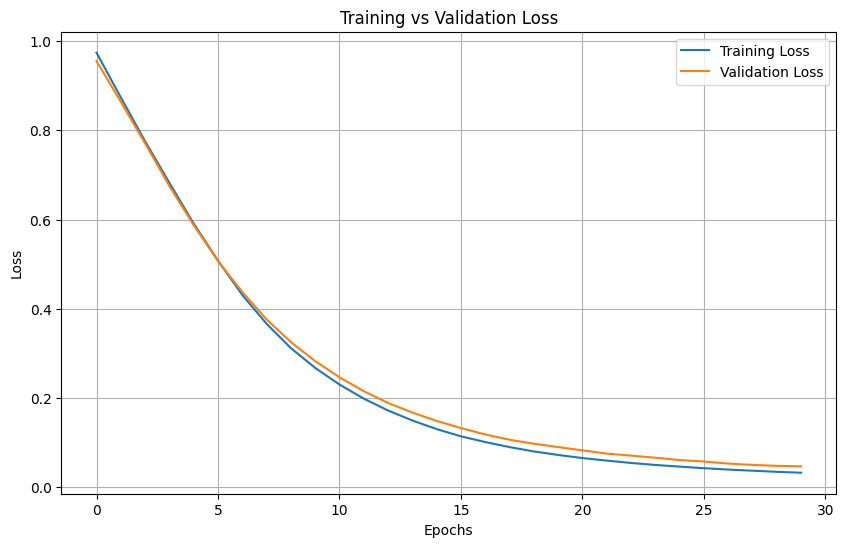

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

In [23]:
loss, acc=ann.evaluate(x_test, y_test, verbose=1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.0294


In [ ]:
#In this problem we used softmax activation function instead of sigmoid in the final layer because the problem is a multi class classification so as we have more 2 classes for the output variable we opted for softmax over sigmoid activation functiona and use the sparse_categorical_crossentropy loss instaed of binary_crossentropy function